Instalación e Importación de Librerías

In [25]:
# ==============================================================================
# BLOQUE 0: INSTALACIÓN E IMPORTACIÓN DE DEPENDENCIAS (Cuaderno 01 y 04)
# ==============================================================================
import io
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn import preprocessing

# Si estás en Google Colab y quieres generar el reporte HTML interactivo:
# !pip install ydata-profiling
try:
    from ydata_profiling import ProfileReport
except ImportError:
    pass

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


/tmp/ipykernel_7425/3180566065.py:15: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


CARGA DE ARCHIVOS Y RECONOCIMIENTO INICIAL

Carga de los 4 ficheros originales

In [26]:
df_edu = pd.read_csv('todas_02.csv', sep=None, engine='python')
df_ine = pd.read_csv('53689.csv', sep=None, engine='python')
df_centros = pd.read_excel('listado_centros.xls')
df_sepe = pd.read_excel('parosexoedadprov.xls', skiprows=6)

Limpieza de caracteres BOM si existen

In [27]:
df_edu.columns = [c.replace('\ufeff', '') for c in df_edu.columns]
df_ine.columns = [c.replace('\ufeff', '') for c in df_ine.columns]

Métodos .shape y .columns de los cuadernos

In [28]:
print("Shape Educación:", df_edu.shape)
print("Shape INE:", df_ine.shape)
print("Shape Centros:", df_centros.shape)
print("Shape SEPE:", df_sepe.shape)

Shape Educación: (13608, 5)
Shape INE: (4920, 7)
Shape Centros: (34843, 10)
Shape SEPE: (64, 13)


Comprobación de valores nulos

In [29]:
print("¿Hay nulos en Educación?:", df_edu.isnull().values.any())
print("¿Hay nulos en INE?:", df_ine.isnull().values.any())
print("¿Hay nulos en Centros?:", df_centros.isnull().values.any())

¿Hay nulos en Educación?: False
¿Hay nulos en INE?: True
¿Hay nulos en Centros?: True


TÉCNICAS DEL CUADERNO 01 (Slicing, loc, apply, lambda, cut, pivot)


Valores únicos en 'Grado de urbanización': ['TOTAL' 'Áreas densamente pobladas' 'Áreas intermedias'
 'Áreas escasamente pobladas']
Valores únicos en 'Titularidad': ['TODOS LOS CENTROS' 'CENTROS PÚBLICOS' 'CENTROS PRIVADOS']

Slicing [10:15]:


,Titularidad/financiación del centro,Comunidad autónoma/provincia,Grado de urbanización,Enseñanza,Total,Total_Num
10,TODOS LOS CENTROS,00 TOTAL,TOTAL,CF Grado Medio a distancia,60.781,60781
11,TODOS LOS CENTROS,00 TOTAL,TOTAL,Cursos de Especialización Grado Medio,808,808
12,TODOS LOS CENTROS,00 TOTAL,TOTAL,Cursos de Especialización Grado Medio a distancia,0,0
13,TODOS LOS CENTROS,00 TOTAL,TOTAL,CF Grado Superior,461.343,461343
14,TODOS LOS CENTROS,00 TOTAL,TOTAL,CF Grado Superior a distancia,164.742,164742



Selección con .loc:


,Comunidad autónoma/provincia,Enseñanza,Total_Num
10,00 TOTAL,CF Grado Medio a distancia,60781
11,00 TOTAL,Cursos de Especialización Grado Medio,808
12,00 TOTAL,Cursos de Especialización Grado Medio a distancia,0
13,00 TOTAL,CF Grado Superior,461343
14,00 TOTAL,CF Grado Superior a distancia,164742
15,00 TOTAL,Cursos de Especialización Grado Superior,6880


Máximo de columnas numéricas (axis=0):
 Total_Num      8316599.000
Total_Miles       8316.599
dtype: float64

Conteo por intervalos de renta (pd.cut y groupby.size):
Renta_Cat
(12756.975, 14771.25]     9
(14771.25, 16777.5]      16
(16777.5, 18783.75]       2
(18783.75, 20790.0]       2
dtype: int64


/tmp/ipykernel_7425/3824972196.py:33: FutureWarning: The provided callable <function sum at 0x78e04cda8900> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  piv_edu = pd.pivot_table(


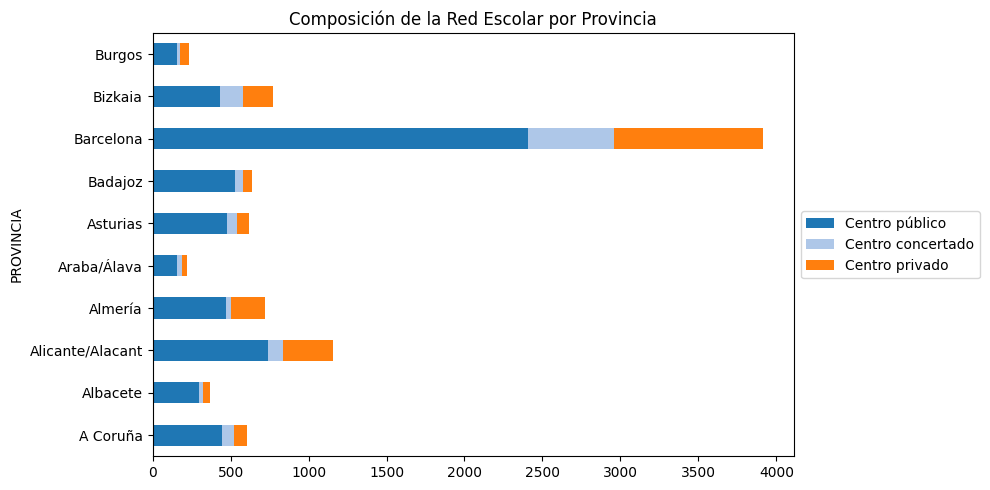

In [30]:
# ==============================================================================
# BLOQUE 2: TÉCNICAS DEL CUADERNO 01 (Slicing, loc, apply, lambda, cut, pivot)
# ==============================================================================
# 1. Limpieza y conversión de tipos con .astype() (Cuaderno 01)
df_edu['Total_Num'] = pd.to_numeric(
    df_edu['Total'].astype(str).str.replace('.', '', regex=False),
    errors='coerce'
).fillna(0)

# 2. Inspección con .head(), .tail() y .unique()
print("\nValores únicos en 'Grado de urbanización':", df_edu['Grado de urbanización'].unique())
print("Valores únicos en 'Titularidad':", df_edu['Titularidad/financiación del centro'].unique())

# 3. Slicing por índice y selección de columnas combinadas con .loc
print("\nSlicing [10:15]:")
display(df_edu[10:15])
print("\nSelección con .loc:")
display(df_edu.loc[10:15, ['Comunidad autónoma/provincia', 'Enseñanza', 'Total_Num']])

# 4. Operaciones matemáticas entre columnas y funciones .apply con np.log y lambda
df_edu['Total_Miles'] = df_edu['Total_Num'] / 1000
df_edu['Log_Total'] = df_edu['Total_Num'].apply(lambda x: np.log(x + 1))
df_edu['Cuadrado_Miles'] = df_edu['Total_Miles'].apply(lambda x: x**2)

# Normalización de columna calculada y eliminación con .drop(..., inplace=True)
df_edu['Total_Norm'] = df_edu['Total_Num'] / df_edu['Total_Num'].max()
df_edu.drop('Total_Norm', axis=1, inplace=True)

# 5. Funciones de agregación en DataFrame (axis=0 y axis=1)
print("Máximo de columnas numéricas (axis=0):\n", df_edu[['Total_Num', 'Total_Miles']].max(axis=0))

# 6. Pivotaje y agregación (pd.pivot_table y groupby)
piv_edu = pd.pivot_table(
    df_edu[(df_edu['Titularidad/financiación del centro'] == 'TODOS LOS CENTROS') &
           (df_edu['Grado de urbanización'] == 'TOTAL')],
    values='Total_Num',
    index='Comunidad autónoma/provincia',
    columns='Enseñanza',
    aggfunc=np.sum,
    fill_value=0
)

# Variable objetivo continua: Ratio FP Básica / Bachillerato
piv_edu['Ratio_FPBasica_Bach'] = piv_edu['CF Grado Básico'] / piv_edu['Bachillerato'].replace(0, np.nan)
df_edu_target = piv_edu[['CF Grado Básico', 'Bachillerato', 'Ratio_FPBasica_Bach']].reset_index()
df_edu_target.columns = ['PROVINCIA', 'Alumnos_FP_Basica', 'Alumnos_Bachillerato', 'Ratio_FPBasica_Bach']
df_edu_target['PROV_NORM'] = df_edu_target['PROVINCIA'].astype(str).str.upper().str.strip()

# Pivotaje de centros (públicos, concertados, privados)
piv_centros = pd.pivot_table(
    df_centros,
    values='CÓDIGO',
    index=['PROVINCIA'],
    columns=['NATURALEZA'],
    aggfunc='count',
    fill_value=0
)
if 'NATURALEZA' in piv_centros.columns:
    piv_centros.drop(columns=['NATURALEZA'], inplace=True, errors='ignore')
piv_centros['Total_Centros'] = piv_centros.sum(axis=1)
piv_centros['Pct_Concertado'] = (piv_centros.get('Centro concertado', 0) / piv_centros['Total_Centros']) * 100
piv_centros['Pct_Publico'] = (piv_centros.get('Centro público', 0) / piv_centros['Total_Centros']) * 100
df_centros_agg = piv_centros.reset_index()
df_centros_agg['PROV_NORM'] = df_centros_agg['PROVINCIA'].astype(str).str.upper().str.strip()

# Procesamiento de INE (Renta media) y SEPE (Paro juvenil)
df_ine_prov = df_ine[(df_ine['Provincias'].notnull()) & (df_ine['Indicadores de renta media'] == 'Renta neta media por persona')].copy()
df_ine_prov['Renta_Num'] = pd.to_numeric(df_ine_prov['Total'].astype(str).str.replace('.', '', regex=False), errors='coerce')
ultimo_año = df_ine_prov.dropna(subset=['Renta_Num'])['Periodo'].max()
df_ine_reciente = df_ine_prov[df_ine_prov['Periodo'] == ultimo_año][['Provincias', 'Renta_Num']].copy()
df_ine_reciente.columns = ['PROVINCIA', 'Renta_Media']
df_ine_reciente['PROV_NORM'] = df_ine_reciente['PROVINCIA'].astype(str).str.upper().str.strip()

df_sepe_clean = df_sepe.iloc[:, [1, 2, 5, 6]].copy()
df_sepe_clean.columns = ['PROVINCIA', 'Paro_Total', 'Paro_Menor25_H', 'Paro_Menor25_M']
df_sepe_clean = df_sepe_clean.dropna(subset=['PROVINCIA'])
df_sepe_clean['Paro_Juvenil_Total'] = df_sepe_clean['Paro_Menor25_H'] + df_sepe_clean['Paro_Menor25_M']
df_sepe_clean['Tasa_Paro_Juvenil'] = (df_sepe_clean['Paro_Juvenil_Total'] / df_sepe_clean['Paro_Total']) * 100
df_sepe_clean['PROV_NORM'] = df_sepe_clean['PROVINCIA'].astype(str).str.upper().str.strip()

# Enlace final del Dataset Maestro
df_master = pd.merge(df_edu_target, df_ine_reciente[['PROV_NORM', 'Renta_Media']], on='PROV_NORM', how='inner')
df_master = pd.merge(df_master, df_sepe_clean[['PROV_NORM', 'Tasa_Paro_Juvenil', 'Paro_Juvenil_Total', 'Paro_Total']], on='PROV_NORM', how='inner')
df_master = pd.merge(df_master, df_centros_agg[['PROV_NORM', 'Total_Centros', 'Pct_Publico', 'Pct_Concertado']], on='PROV_NORM', how='inner')

# 7. Discretización en intervalos con pd.cut() y conteos groupby.size()
df_master['Renta_Cat'] = pd.cut(df_master['Renta_Media'], bins=4)
print("\nConteo por intervalos de renta (pd.cut y groupby.size):")
print(df_master.groupby('Renta_Cat', observed=False).size())

# 8. Gráfico de barras apiladas horizontales (Cuaderno 01)
my_colors = ['#1f77b4', '#aec7e8', '#ff7f0e']
ax = piv_centros.head(10)[['Centro público', 'Centro concertado', 'Centro privado']].plot(
    kind='barh', stacked=True, color=my_colors, figsize=(10, 5)
)
ax.set_title("Composición de la Red Escolar por Provincia")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

Estadística Descriptiva Completa

Resumen estadístico con .describe():


,Renta_Media,Ratio_FPBasica_Bach
count,29.000000,29.000000
mean,15391.586207,0.146503
std,1917.252508,0.064134
min,12765.000000,0.008670
25%,13827.000000,0.130760
50%,15364.000000,0.157380
75%,16095.000000,0.183955
max,20790.000000,0.295033



Mediana de la ratio formativa según nivel de renta:
Renta_Cat
(12756.975, 14771.25]    0.158085
(14771.25, 16777.5]      0.156800
(16777.5, 18783.75]      0.088300
(18783.75, 20790.0]      0.164276
Name: Ratio_FPBasica_Bach, dtype: float64


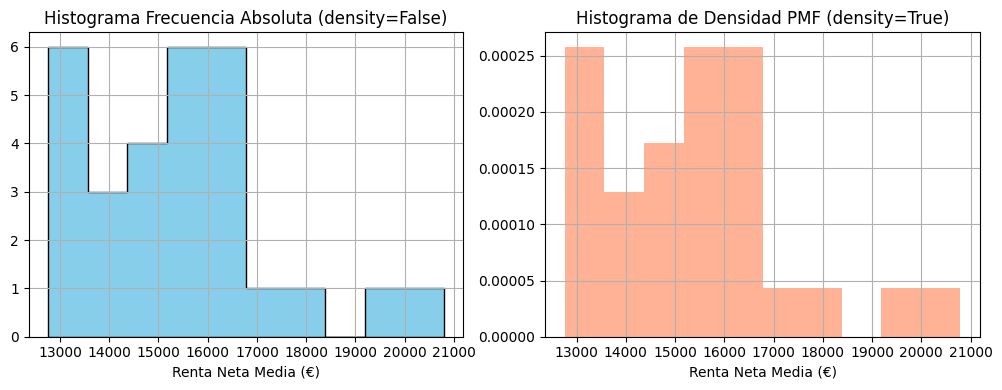

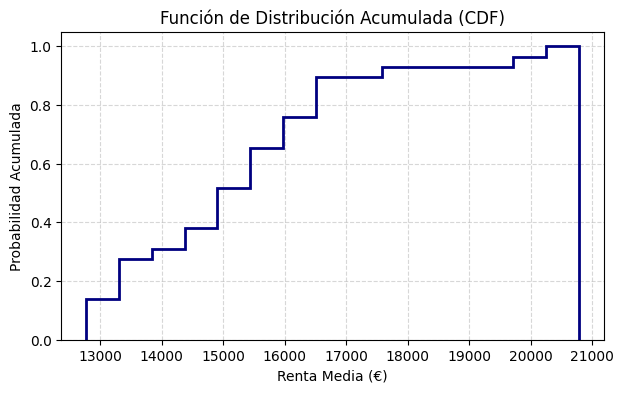


Regla de detección de Outliers: Rango normal [11557.1, 19226.1]
Filas originales: 29 | Filas tras depurar outliers: 27


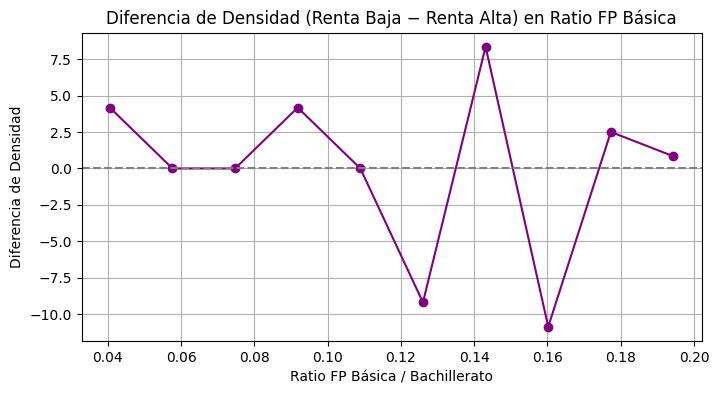


Asimetría de Pearson (Renta Media): 0.043165217069824284
Asimetría de Pearson (Ratio FP Básica): -0.5088157952348251


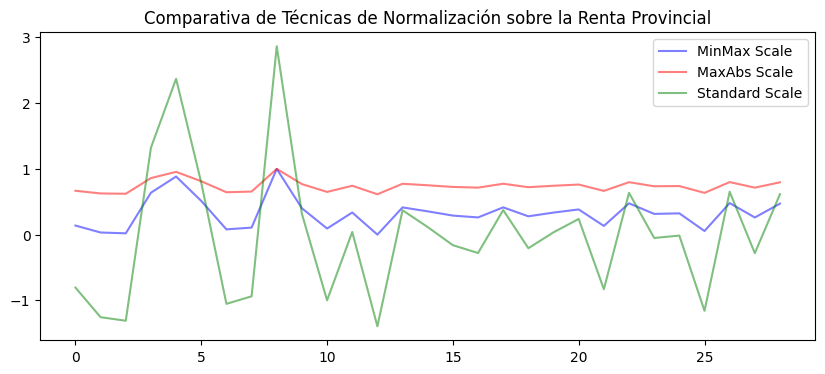

In [31]:
# ==============================================================================
# BLOQUE 3: TÉCNICAS DEL CUADERNO 02 (Descriptiva, CDF, Outliers, Skew, Scaling)
# ==============================================================================
# 1. Resumen descriptivo general y por tramo
print("Resumen estadístico con .describe():")
display(df_master[['Renta_Media', 'Tasa_Paro_Juvenil', 'Ratio_FPBasica_Bach']].describe())

# Describe y medianas agrupadas por categoría
print("\nMediana de la ratio formativa según nivel de renta:")
print(df_master.groupby('Renta_Cat', observed=False)['Ratio_FPBasica_Bach'].median())

# 2. Histograma clásico (density=False) y normalizado como PMF (density=True)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
df_master['Renta_Media'].hist(density=False, histtype='stepfilled', bins=10, color='skyblue', edgecolor='black')
plt.title("Histograma Frecuencia Absoluta (density=False)")
plt.xlabel("Renta Neta Media (€)")

plt.subplot(1, 2, 2)
df_master['Renta_Media'].hist(density=True, alpha=0.6, histtype='stepfilled', bins=10, color='coral')
plt.title("Histograma de Densidad PMF (density=True)")
plt.xlabel("Renta Neta Media (€)")
plt.tight_layout()
plt.show()

# 3. Función de Distribución Acumulada (CDF - cumulative=True)
plt.figure(figsize=(7, 4))
df_master['Renta_Media'].hist(density=True, cumulative=True, histtype='step', bins=15, linewidth=2, color='navy')
plt.title("Función de Distribución Acumulada (CDF)")
plt.xlabel("Renta Media (€)")
plt.ylabel("Probabilidad Acumulada")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 4. Detección y filtrado de Outliers mediante la regla (mean ± 2 * std)
mean_val = df_master['Renta_Media'].mean()
std_val = df_master['Renta_Media'].std()
print(f"\nRegla de detección de Outliers: Rango normal [{mean_val - 2*std_val:.1f}, {mean_val + 2*std_val:.1f}]")

df_sin_outliers = df_master.drop(
    df_master.index[(df_master['Renta_Media'] > mean_val + 2 * std_val) |
                    (df_master['Renta_Media'] < mean_val - 2 * std_val)]
)
print(f"Filas originales: {len(df_master)} | Filas tras depurar outliers: {len(df_sin_outliers)}")

# 5. Diferencia de histogramas de densidad entre 2 subgrupos (Cuaderno 02)
# Dividimos en dos grupos: Provincias con Renta Alta vs. Renta Baja
mediana_r = df_master['Renta_Media'].median()
g_baja = df_master[df_master['Renta_Media'] < mediana_r]['Ratio_FPBasica_Bach']
g_alta = df_master[df_master['Renta_Media'] >= mediana_r]['Ratio_FPBasica_Bach']

count_baja, div_baja = np.histogram(g_baja, bins=10, density=True)
count_alta, div_alta = np.histogram(g_alta, bins=div_baja, density=True)
val_centers = [(div_baja[i] + div_baja[i+1]) / 2 for i in range(len(div_baja) - 1)]

plt.figure(figsize=(8, 4))
plt.plot(val_centers, count_baja - count_alta, marker='o', color='purple')
plt.axhline(0, color='grey', linestyle='--')
plt.title("Diferencia de Densidad (Renta Baja − Renta Alta) en Ratio FP Básica")
plt.xlabel("Ratio FP Básica / Bachillerato")
plt.ylabel("Diferencia de Densidad")
plt.grid(True)
plt.show()

# 6. Coeficiente de Asimetría de Pearson (Pearson Skewness)
def pearson_skewness(series):
    return 3 * (series.mean() - series.median()) / series.std(ddof=1)

print("\nAsimetría de Pearson (Renta Media):", pearson_skewness(df_master['Renta_Media']))
print("Asimetría de Pearson (Ratio FP Básica):", pearson_skewness(df_master['Ratio_FPBasica_Bach']))

# 7. Técnicas de Normalización (MinMax, MaxAbs y StandardScaler)
df_master['renta_minmax'] = preprocessing.minmax_scale(df_master['Renta_Media'])
df_master['renta_maxabs'] = preprocessing.maxabs_scale(df_master['Renta_Media'])
df_master['renta_std'] = preprocessing.scale(df_master['Renta_Media'])

plt.figure(figsize=(10, 4))
df_master['renta_minmax'].plot(alpha=0.5, color='blue', label='MinMax Scale')
df_master['renta_maxabs'].plot(alpha=0.5, color='red', label='MaxAbs Scale')
df_master['renta_std'].plot(alpha=0.5, color='green', label='Standard Scale')
plt.title("Comparativa de Técnicas de Normalización sobre la Renta Provincial")
plt.legend()
plt.show()

Estadística Inferencial, Bootstrap y Contraste de Hipótesis

Media mediante simulación de muestreo: 15399.72 €
Media real de toda la muestra: 15391.59 €


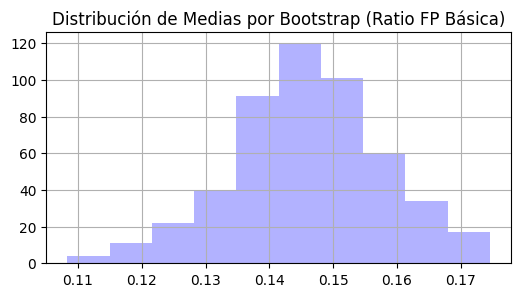

,PROVINCIA,Alumnos_FP_Basica,Alumnos_Bachillerato,Ratio_FPBasica_Bach,PROV_NORM,Renta_Media,Tasa_Paro_Juvenil,Paro_Juvenil_Total,Paro_Total,Total_Centros,Pct_Publico,Pct_Concertado,Renta_Cat,renta_minmax,renta_maxabs,renta_std
19,Salamanca,658,4212,0.156220,SALAMANCA,15458.0,9.86933,1571,15918,261,72.030651,8.812261,"(14771.25, 16777.5]",0.335576,0.743531,0.035253
7,Cuenca,455,2374,0.191660,CUENCA,13624.0,8.751637,802,9164,207,89.371981,4.347826,"(12756.975, 14771.25]",0.107040,0.655315,-0.938256
28,Zaragoza,2110,13407,0.157380,ZARAGOZA,16551.0,9.724149,3786,38934,647,66.769706,13.446677,"(14771.25, 16777.5]",0.471776,0.796104,0.615431
12,Huelva,1133,6912,0.163918,HUELVA,12765.0,10.885756,3011,27660,490,75.714286,6.530612,"(12756.975, 14771.25]",0.000000,0.613997,-1.394223
18,Pontevedra,2015,12761,0.157903,PONTEVEDRA,15002.0,4.829404,2034,42117,630,67.936508,13.650794,"(14771.25, 16777.5]",0.278754,0.721597,-0.206797


,PROVINCIA,Alumnos_FP_Basica,Alumnos_Bachillerato,Ratio_FPBasica_Bach,PROV_NORM,Renta_Media,Tasa_Paro_Juvenil,Paro_Juvenil_Total,Paro_Total,Total_Centros,Pct_Publico,Pct_Concertado,Renta_Cat,renta_minmax,renta_maxabs,renta_std
19,Salamanca,658,4212,0.156220,SALAMANCA,15458.0,9.86933,1571,15918,261,72.030651,8.812261,"(14771.25, 16777.5]",0.335576,0.743531,0.035253
5,Burgos,798,4752,0.167929,BURGOS,16879.0,9.030903,1204,13332,231,67.532468,9.523810,"(16777.5, 18783.75]",0.512648,0.811881,0.789537
25,Toledo,1947,11076,0.175785,TOLEDO,13208.0,8.420839,3737,44378,579,80.656304,8.117444,"(12756.975, 14771.25]",0.055202,0.635305,-1.159074
10,Granada,1897,14164,0.133931,GRANADA,13509.0,9.726935,6077,62476,922,64.316703,8.893709,"(12756.975, 14771.25]",0.092710,0.649784,-0.999299
27,Zamora,227,1736,0.130760,ZAMORA,14861.0,7.972751,632,7927,141,82.978723,4.255319,"(14771.25, 16777.5]",0.261184,0.714815,-0.281641


,PROVINCIA,Alumnos_FP_Basica,Alumnos_Bachillerato,Ratio_FPBasica_Bach,PROV_NORM,Renta_Media,Tasa_Paro_Juvenil,Paro_Juvenil_Total,Paro_Total,Total_Centros,Pct_Publico,Pct_Concertado,Renta_Cat,renta_minmax,renta_maxabs,renta_std
27,Zamora,227,1736,0.130760,ZAMORA,14861.0,7.972751,632,7927,141,82.978723,4.255319,"(14771.25, 16777.5]",0.261184,0.714815,-0.281641
16,Ourense,616,3302,0.186554,OURENSE,14865.0,5.892268,804,13645,203,73.399015,12.315271,"(14771.25, 16777.5]",0.261682,0.715007,-0.279518
12,Huelva,1133,6912,0.163918,HUELVA,12765.0,10.885756,3011,27660,490,75.714286,6.530612,"(12756.975, 14771.25]",0.000000,0.613997,-1.394223
22,Soria,139,1183,0.117498,SORIA,16589.0,12.393637,335,2703,96,84.375000,3.125000,"(14771.25, 16777.5]",0.476511,0.797932,0.635602
8,Gipuzkoa,1502,11404,0.131708,GIPUZKOA,20790.0,9.925916,2894,29156,551,60.980036,20.145191,"(18783.75, 20790.0]",1.000000,1.000000,2.865542



Intervalo de Confianza Teórico 95%: [0.1232, 0.1698]
Intervalo de Confianza Bootstrap 95%: [0.1206, 0.1694]

Media Grupo Renta Baja: 0.1494 | IC 95%: [np.float64(0.12631766643883433), np.float64(0.1724166264521572)]
Media Grupo Renta Alta: 0.1438 | IC 95%: [np.float64(0.10330437308679132), np.float64(0.18435529713637394)]

=== CONTRASTE T DE STUDENT ===
Estadístico t: 0.23279092180386096
p-value (dos colas): 0.8180720880125676
p-value (una cola): 0.4090360440062838
Conclusión: No hay evidencia suficiente para rechazar H0.


In [32]:
# ==============================================================================
# BLOQUE 4: TÉCNICAS DEL CUADERNO 03 (Muestreo, Bootstrap, IC, Test de Hipótesis)
# ==============================================================================
# 1. Simulación de experimentos de muestreo sin reemplazo (np.random.choice)
n_test = 200
elements = 10
means_sim = [0] * n_test
for i in range(n_test):
    rows = np.random.choice(df_master.index.values, elements)
    sampled_df = df_master.iloc[rows]['Renta_Media']
    means_sim[i] = sampled_df.mean()

print(f"Media mediante simulación de muestreo: {np.mean(means_sim):.2f} €")
print(f"Media real de toda la muestra: {df_master['Renta_Media'].mean():.2f} €")

# 2. Función de Bootstraping con reemplazo (Cuaderno 03)
def meanBootstrap(X, numberb):
    x = [0] * numberb
    for i in range(numberb):
        sample = [X.iloc[j] for j in np.random.randint(len(X), size=len(X))]
        x[i] = np.mean(sample)
    return x

m_boot = meanBootstrap(df_master['Ratio_FPBasica_Bach'], 500)
pd.DataFrame(m_boot).hist(alpha=0.3, color='blue', figsize=(6, 3))
plt.title("Distribución de Medias por Bootstrap (Ratio FP Básica)")
plt.show()

# 3. Métodos .sample() propios de Pandas
display(df_master.sample(5))                                   # Muestra aleatoria de 5 filas
display(df_master.sample(frac=0.3, replace=True).head(5))      # 30% con reemplazo
display(df_master.sample(n=5, random_state=42))               # Semilla fija reproducible

# 4. Intervalos de Confianza al 95%:
# A) Fórmula teórica: Mean ± 1.96 * SE
m_teo = df_master['Ratio_FPBasica_Bach'].mean()
se_teo = df_master['Ratio_FPBasica_Bach'].std() / math.sqrt(len(df_master['Ratio_FPBasica_Bach']))
ci_teorico = [m_teo - se_teo * 1.96, m_teo + se_teo * 1.96]
print(f"\nIntervalo de Confianza Teórico 95%: [{ci_teorico[0]:.4f}, {ci_teorico[1]:.4f}]")

# B) Percentiles empíricos de Bootstrap (2.5% y 97.5%)
ci_boot = [np.percentile(m_boot, 2.5), np.percentile(m_boot, 97.5)]
print(f"Intervalo de Confianza Bootstrap 95%: [{ci_boot[0]:.4f}, {ci_boot[1]:.4f}]")

# 5. Contraste de Hipótesis y Cálculo de p-value mediante t de Student (Welch)
# H0: No hay diferencia en la ratio formativa entre provincias de renta baja y alta.
# Ha: Las provincias con menor renta tienen una ratio de FP Básica significativamente superior.
ci_baja = [g_baja.mean() - g_baja.std() * 1.96 / np.sqrt(len(g_baja)),
           g_baja.mean() + g_baja.std() * 1.96 / np.sqrt(len(g_baja))]
ci_alta = [g_alta.mean() - g_alta.std() * 1.96 / np.sqrt(len(g_alta)),
           g_alta.mean() + g_alta.std() * 1.96 / np.sqrt(len(g_alta))]

print(f"\nMedia Grupo Renta Baja: {g_baja.mean():.4f} | IC 95%: {ci_baja}")
print(f"Media Grupo Renta Alta: {g_alta.mean():.4f} | IC 95%: {ci_alta}")

# Prueba t de Student para varianzas heterogéneas
ttest_res = stats.ttest_ind(g_baja, g_alta, equal_var=False)
p_value_una_cola = ttest_res.pvalue / 2

print("\n=== CONTRASTE T DE STUDENT ===")
print("Estadístico t:", ttest_res.statistic)
print("p-value (dos colas):", ttest_res.pvalue)
print("p-value (una cola):", p_value_una_cola)

if p_value_una_cola < 0.05:
    print("Conclusión: p < 0.05. Se rechaza H0 y se acepta la Hipótesis Alternativa con 95% de confianza.")
else:
    print("Conclusión: No hay evidencia suficiente para rechazar H0.")

Generación del Reporte Automatizado con Profiling

In [33]:
!pip install ydata-profiling

In [34]:
# ==============================================================================
# BLOQUE 5: TÉCNICA DEL CUADERNO 04 (Pandas / YData Profiling)
# ==============================================================================
# Selección de columnas numéricas y continuas representativas para el informe masivo
df_para_reporte = df_master[[
    'Ratio_FPBasica_Bach', 'Renta_Media', 'Tasa_Paro_Juvenil',
    'Pct_Publico', 'Pct_Concertado', 'Alumnos_FP_Basica', 'Alumnos_Bachillerato'
]]

# Creación del perfil exploratorio
profile = ProfileReport(
    df_para_reporte,
    title="Reporte Exploratorio Completo - Vulnerabilidad Educativa y Renta",
    html={'style': {'full_width': True}}
)

# Exportación a formato HTML interactivo
profile.to_file("Reporte_Profiling_Completo.html")
print("Reporte interactivo guardado como 'Reporte_Profiling_Completo.html'.")

/usr/local/lib/python3.13/dist-packages/ydata_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:00<00:00, 210.03it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte interactivo guardado como 'Reporte_Profiling_Completo.html'.
